In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data

In [5]:
#dataset = pd.read_csv('customer_churn_dataset-training-master1.csv')
# dataset = pd.read_csv('customer_churn_dataset-testing-master2.csv')
dataset = pd.read_csv('Customer Churn.csv')
# dataset = pd.read_csv('customer_churn_dataset-training-master - customer_churn_dataset-training-master3.csv')

dataset = pd.read_csv('dataset.csv')


# url_telco = 'https://github.com/YBIFoundation/Dataset/raw/main/TelecomCustomerChurn.csv'
# dataset = pd.read_csv(url_telco)

# url_telco = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
# df_telco = pd.read_csv(url_telco)

# url_bank = 'https://raw.githubusercontent.com/YBI-Foundation/Dataset/main/Bank%20Churn.csv'
# df_bank = pd.read_csv(url_bank)

print(f"Kích thước dữ liệu gốc: {dataset.shape[0]} dòng (ngày), {dataset.shape[1]} cột (bang)")
dataset.head(3)

Kích thước dữ liệu gốc: 64374 dòng (ngày), 12 cột (bang)


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0


In [6]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         64374 non-null  int64
 1   Age                64374 non-null  int64
 2   Gender             64374 non-null  str  
 3   Tenure             64374 non-null  int64
 4   Usage Frequency    64374 non-null  int64
 5   Support Calls      64374 non-null  int64
 6   Payment Delay      64374 non-null  int64
 7   Subscription Type  64374 non-null  str  
 8   Contract Length    64374 non-null  str  
 9   Total Spend        64374 non-null  int64
 10  Last Interaction   64374 non-null  int64
 11  Churn              64374 non-null  int64
dtypes: int64(9), str(3)
memory usage: 5.9 MB


In [7]:
dataset.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


- CustomerID: Mã định danh duy nhất cho mỗi khách hàng.
- Age: Tuổi của khách hàng.
- Gender: Giới tính của khách hàng (Nam hoặc Nữ).
- Tenure: Số tháng khách hàng đã sử dụng dịch vụ.
- Usage Frequency: Tần suất sử dụng dịch vụ của khách hàng.
- Support Calls: Số cuộc gọi mà khách hàng đã thực hiện tới bộ phận hỗ trợ.
- Payment Delay: Số lần thanh toán bị chậm (tính bằng ngày).
- Subscription Type: Loại gói đăng ký của khách hàng (ví dụ: Cơ bản, Tiêu chuẩn).
- Contract Length: Thời hạn hợp đồng (ví dụ: Hàng tháng, Hàng quý, Hàng năm).
- Total Spend: Tổng số tiền mà khách hàng đã chi tiêu.
- Last Interaction: Số ngày từ lần tương tác gần nhất với công ty.
- Churn: Giá trị nhị phân cho biết khách hàng có rời bỏ dịch vụ hay không (1: rời bỏ, 0: tiếp tục sử dụng dịch vụ).

# Clean data

## Kiểm tra dữ liệu bị thiếu

In [8]:
dataset.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [9]:
dataset.dropna(inplace=True)

C:\Users\LuongTran\AppData\Local\Temp\ipykernel_8228\2639109627.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dataset.dropna(inplace=True)


In [10]:
dataset.isna().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

## Giá trị trùng lập

In [11]:
dataset.duplicated().sum()

np.int64(0)

# Visualize data

## 1. Phân tích phân phối các biến

C:\Users\LuongTran\AppData\Local\Temp\ipykernel_8228\1956891091.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_counts.index, y=churn_counts.values, palette='viridis')


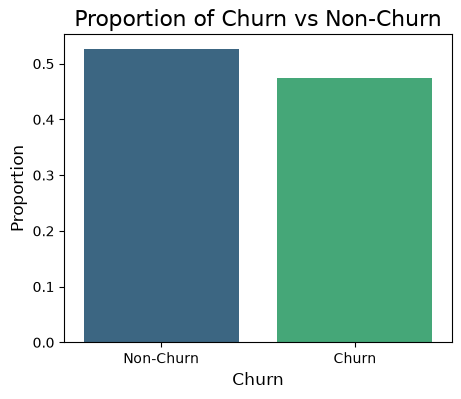

In [12]:
# Checking churn proportions
plt.figure(figsize=(5,4))
churn_counts = dataset['Churn'].value_counts(normalize=True)
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette='viridis')
plt.title('Proportion of Churn vs Non-Churn', fontsize=16)
plt.xlabel('Churn', fontsize=12)
plt.ylabel('Proportion', fontsize=12)
plt.xticks([0, 1], ['Non-Churn', 'Churn'])
plt.show()

Tỷ lệ Churn (Proportion of Churn)[customer_churn_dataset-testing-master2]:
- Churn = 1 (Rời bỏ): Chiếm tỷ lệ cao hơn (khoảng 55%).
- Churn = 0 (Không rời bỏ): Chiếm khoảng 45%.

Kết luận: Số lượng khách hàng rời bỏ dịch vụ (55%) cao hơn số lượng khách hàng tiếp tục sử dụng dịch vụ (45%)

C:\Users\LuongTran\AppData\Local\Temp\ipykernel_8228\657777301.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=dataset, palette='viridis', ax=axes[i])
C:\Users\LuongTran\AppData\Local\Temp\ipykernel_8228\657777301.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=dataset, palette='viridis', ax=axes[i])
C:\Users\LuongTran\AppData\Local\Temp\ipykernel_8228\657777301.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=col, data=dataset, palette='viridis', ax=axes[i])


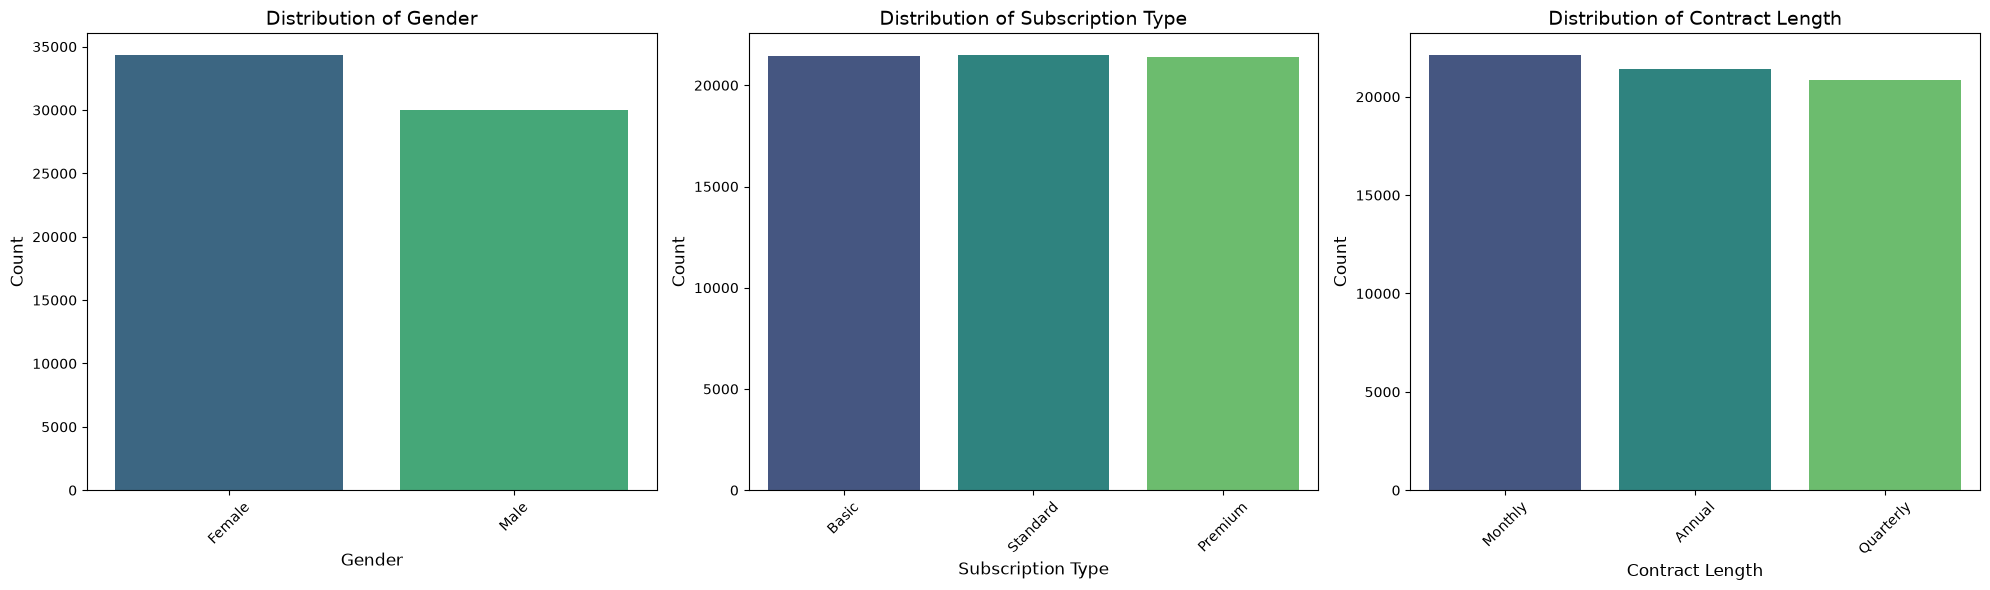

In [13]:
categorical_cols = ['Gender', 'Subscription Type', 'Contract Length']

# Plotting distribution (frequency counts) for categorical variables
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot bar plots for each categorical variable
for i, col in enumerate(categorical_cols):
    sns.countplot(x=col, data=dataset, palette='viridis', ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Các feautures phân loại (Categorical feautures):

1. Gender (Giới tính): Số lượng khách hàng nam (Male) chiếm tỷ lệ lớn hơn nữ khách hàng (Female).

2. Subscription Type (Loại gói dịch vụ): Số lượng khách hàng ở ba gói dịch vụ Basic, Standard, và Premium gần như tương đương, gói Basic thấp hơn một xíu so với 2 loại còn lại

3. Contract Length (Thời hạn hợp đồng): Loại hợp đồng dài hạn (Hàng năm - Annual, Hàng quý - Quarterly) phổ biến hơn hẳn so với hợp đồng ngắn hạn (Hàng tháng - Monthly)


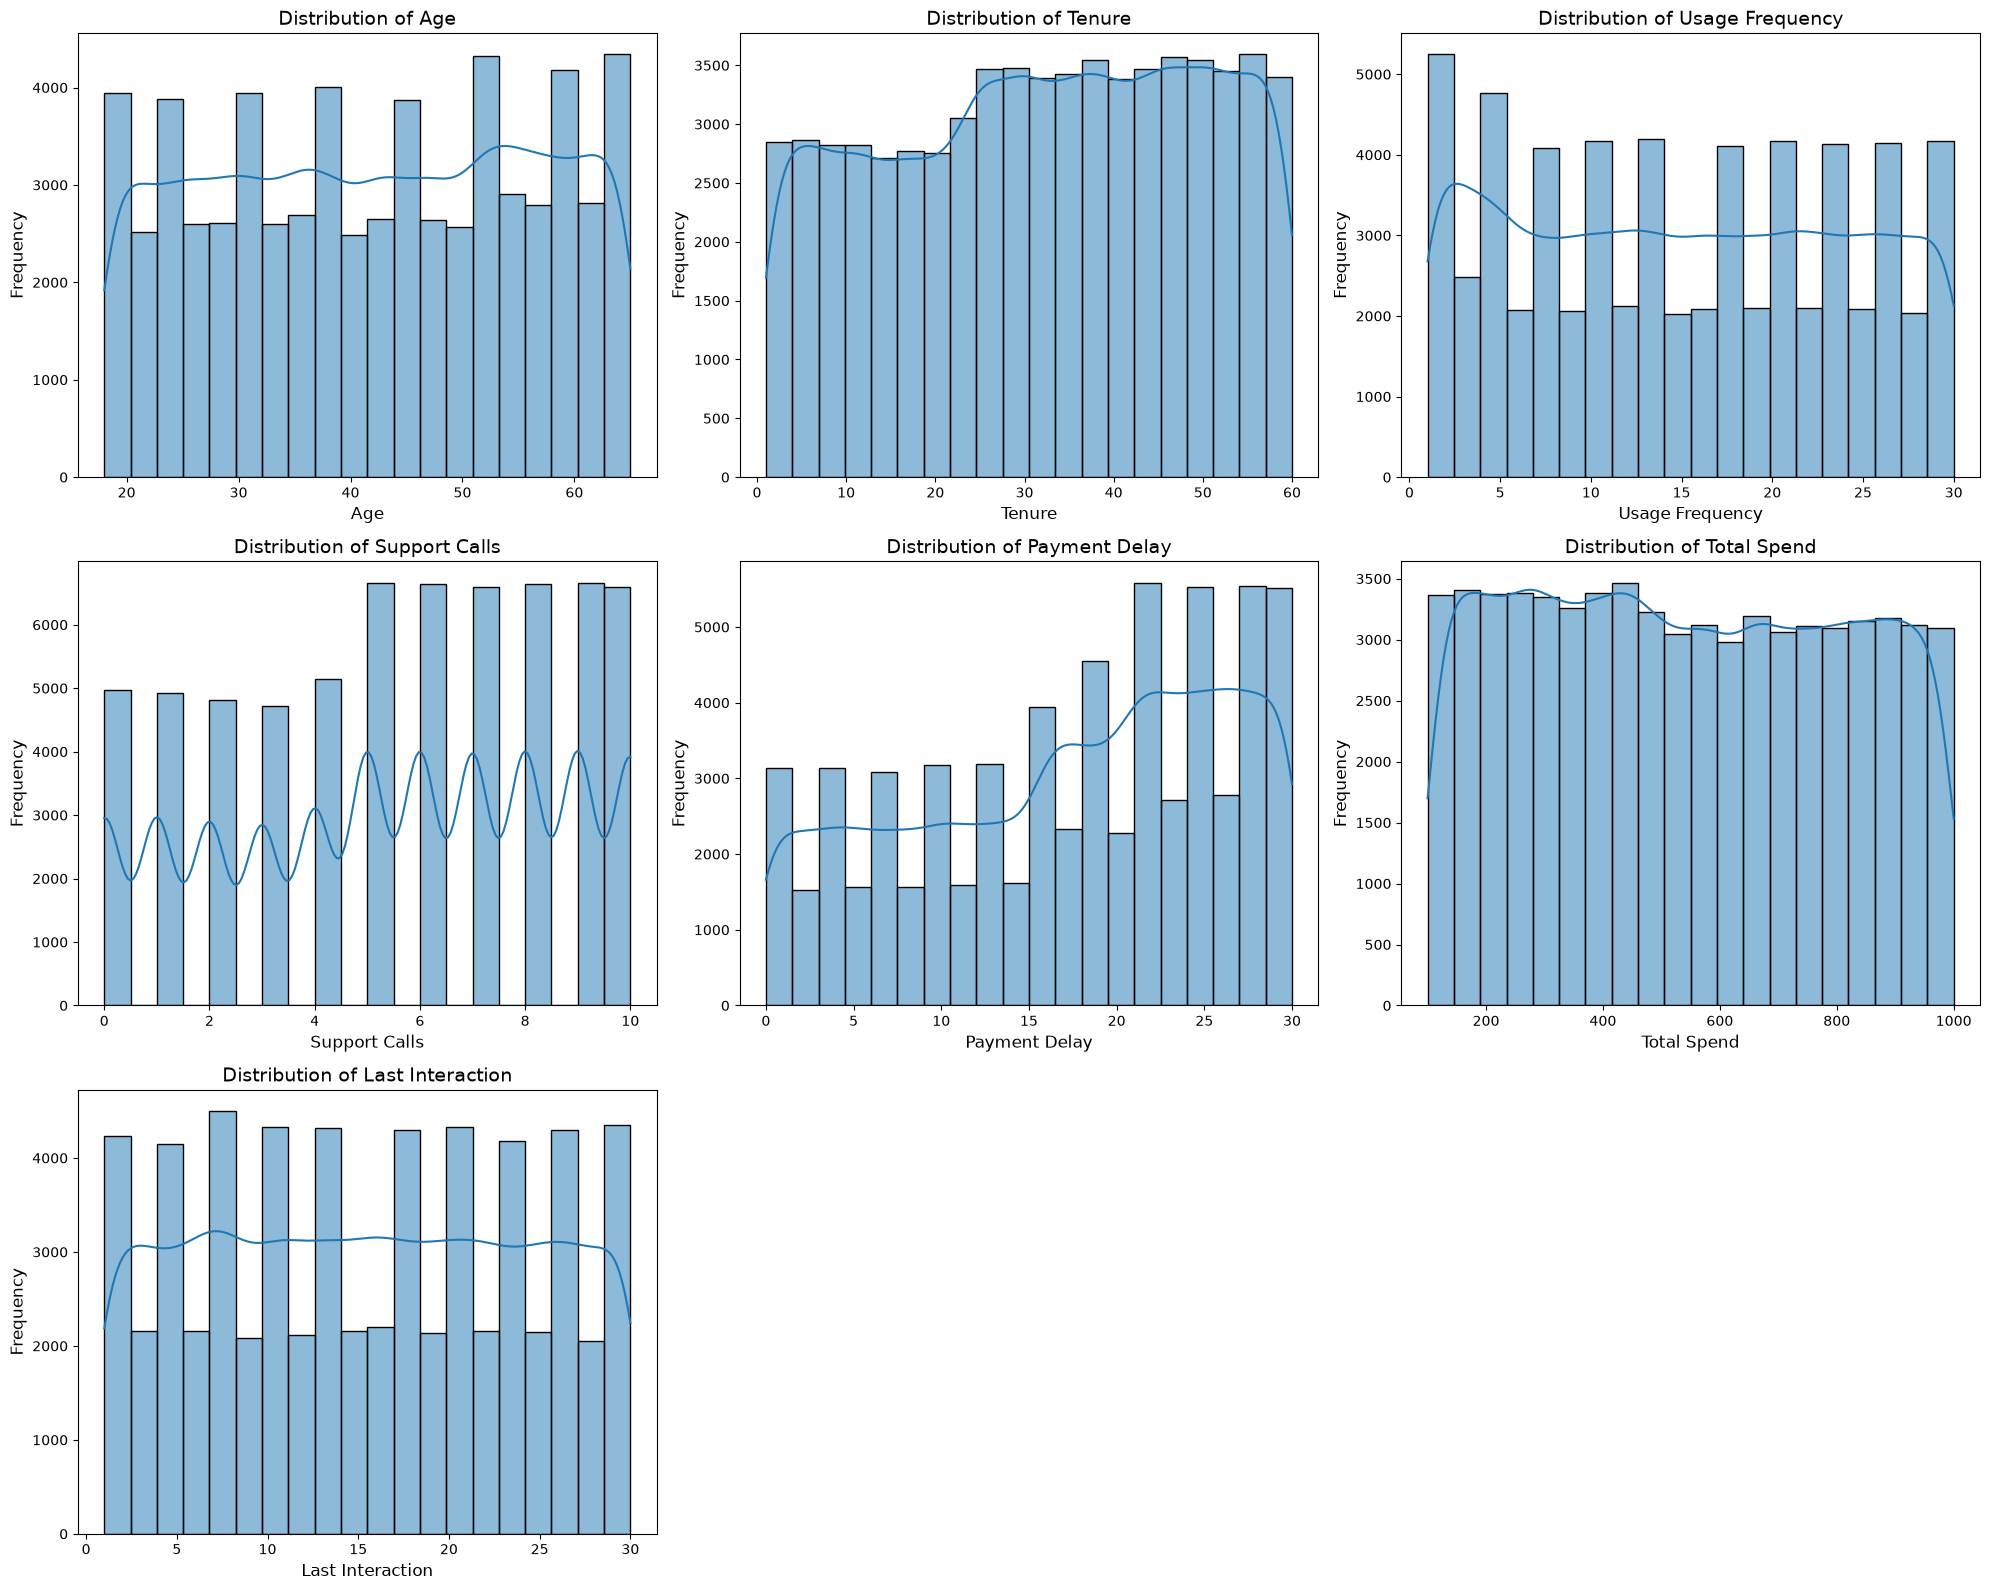

In [14]:
numerical_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']

# Plot histograms for numerical variables
fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(dataset[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Frequency', fontsize=12)

# Remove empty subplot
fig.delaxes(axes[-1])
fig.delaxes(axes[-2])

plt.tight_layout()
plt.show()

Các biến số (Numerical Variables):
1. Age (Tuổi): Dữ liệu được phân bổ khá đều, với một số đỉnh ở nhóm tuổi từ 30-50 và giảm mạnh ở nhóm tuổi trên 60.

2. Tenure (Thời gian sử dụng): Thời gian sử dụng dịch vụ trải rộng đều từ 0 đến 60 tháng. Số lượng khách hàng sử dụng trên 30 tháng nhiều

3. Usage Frequency (Tần suất sử dụng): Tần suất sử dụng tập trung vào mức trung bình, cho thấy phần lớn khách hàng duy trì mức độ sử dụng ổn định.

4. Support Calls (Số lần gọi hỗ trợ): Số lượng gọi hỗ trợ giảm dần từ 0 đến 10 lần. Phần lớn khách hàng gọi hỗ trợ rất ít, đa số khách hàng gọi dưới 3 lần, nhưng cũng có vài trường hợp gọi rất nhiều lần

5. Payment Delay (Trễ hạn thanh toán): Phần lớn khách hàng chậm thanh toán ở mức thấp (khoảng 0 đến trước 20 ngày), nhưng một phần nhỏ chậm thanh toán đáng kể (hơn 20 ngày) có thể là tín hiệu của khách hàng gặp vấn đề tài chính và dễ rời bỏ.

6. Total Spend (Tổng chi tiêu): Tổng chi tiêu có xu hướng tăng từ 0 - 1000 đơn vị, tăng mạnh trong khoảng (450, 550). Phần lớn khách hàng đều chi tiêu ở mức cao (> 550)

7. Last Interaction (Thời gian tương tác cuối cùng): Phần lớn khách hàng có sự tương tác gần đây ở mức trung bình (~14 ngày), nhưng một số khách hàng không nhỏ không tương tác với hệ thống trong thời gian dài (> 16,17 ngày)

## 2. Phân tích mối quan hệ giữa các biến và `Churn`

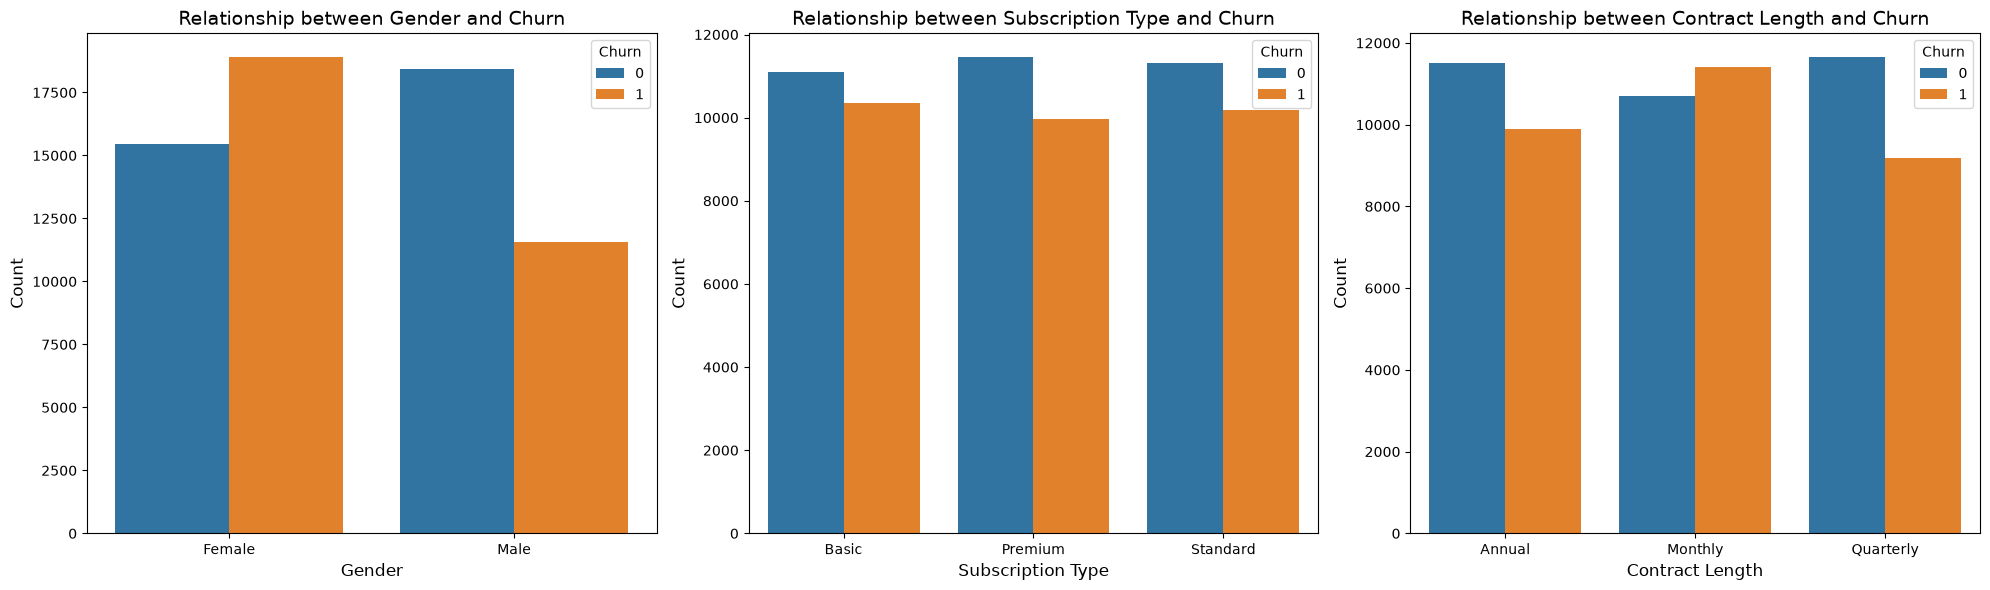

In [15]:
# Create subplots for categorical variables and their relationship with 'Churn'
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

for i, col in enumerate(categorical_cols):
    churn_counts = dataset.groupby([col, 'Churn']).size().reset_index(name='Count')
    sns.barplot(x=col, y='Count', hue='Churn', data=churn_counts, ax=axes[i])
    axes[i].set_title(f'Relationship between {col} and Churn', fontsize=14)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_ylabel('Count', fontsize=12)
    axes[i].legend(title='Churn')

plt.tight_layout()
plt.show()

Đặc trưng phân loại (Categorical features):

1. Gender (Giới tính): Có sự khác biệt rõ rệt giữa 2 giới tính:
- Số lượng khách hàng nam rời đi ít hơn so với khách hàng nữ
- Đối với khách hàng nam, số lượng khách hàng tiếp tục ở lại sử dụng dịch vụ (`churn=0`) cao hơn số lượng rời đi
- Ngược lại, đối với khách hàng nữ, số lượng khách hàng rời đi khoảng gấp đôi so với số lượng ở lại

2. Subscription Type (Loại gói dịch vụ):
- Gói "Basic" có tỷ lệ churn cao hơn so với "Standard" và "Premium" -> Gói cao cấp hơn giữ chân khách hàng tốt hơn.

3. Contract Length (Thời hạn hợp đồng):
- Hợp đồng "Monthly" có tỷ lệ churn cao hơn đáng kể so với "Annual" và "Quarterly". Cụ thể, hầu hết khách hàng sử dụng gói "Monthly" sẽ không tiếp tục sử dụng dịch vụ. Trong khi đó, hợp đồng dài hạn giúp giữ chân khách hàng hiệu quả hơn.

Kết luận: Nên có các chiến lược kinh doanh dịch vụ tập trung vào khách hàng Nữ nhiều hơn, đồng thời, cũng nên có các chiến lược cải thiện giá trị gói Basic và loại hợp đồng Monthly

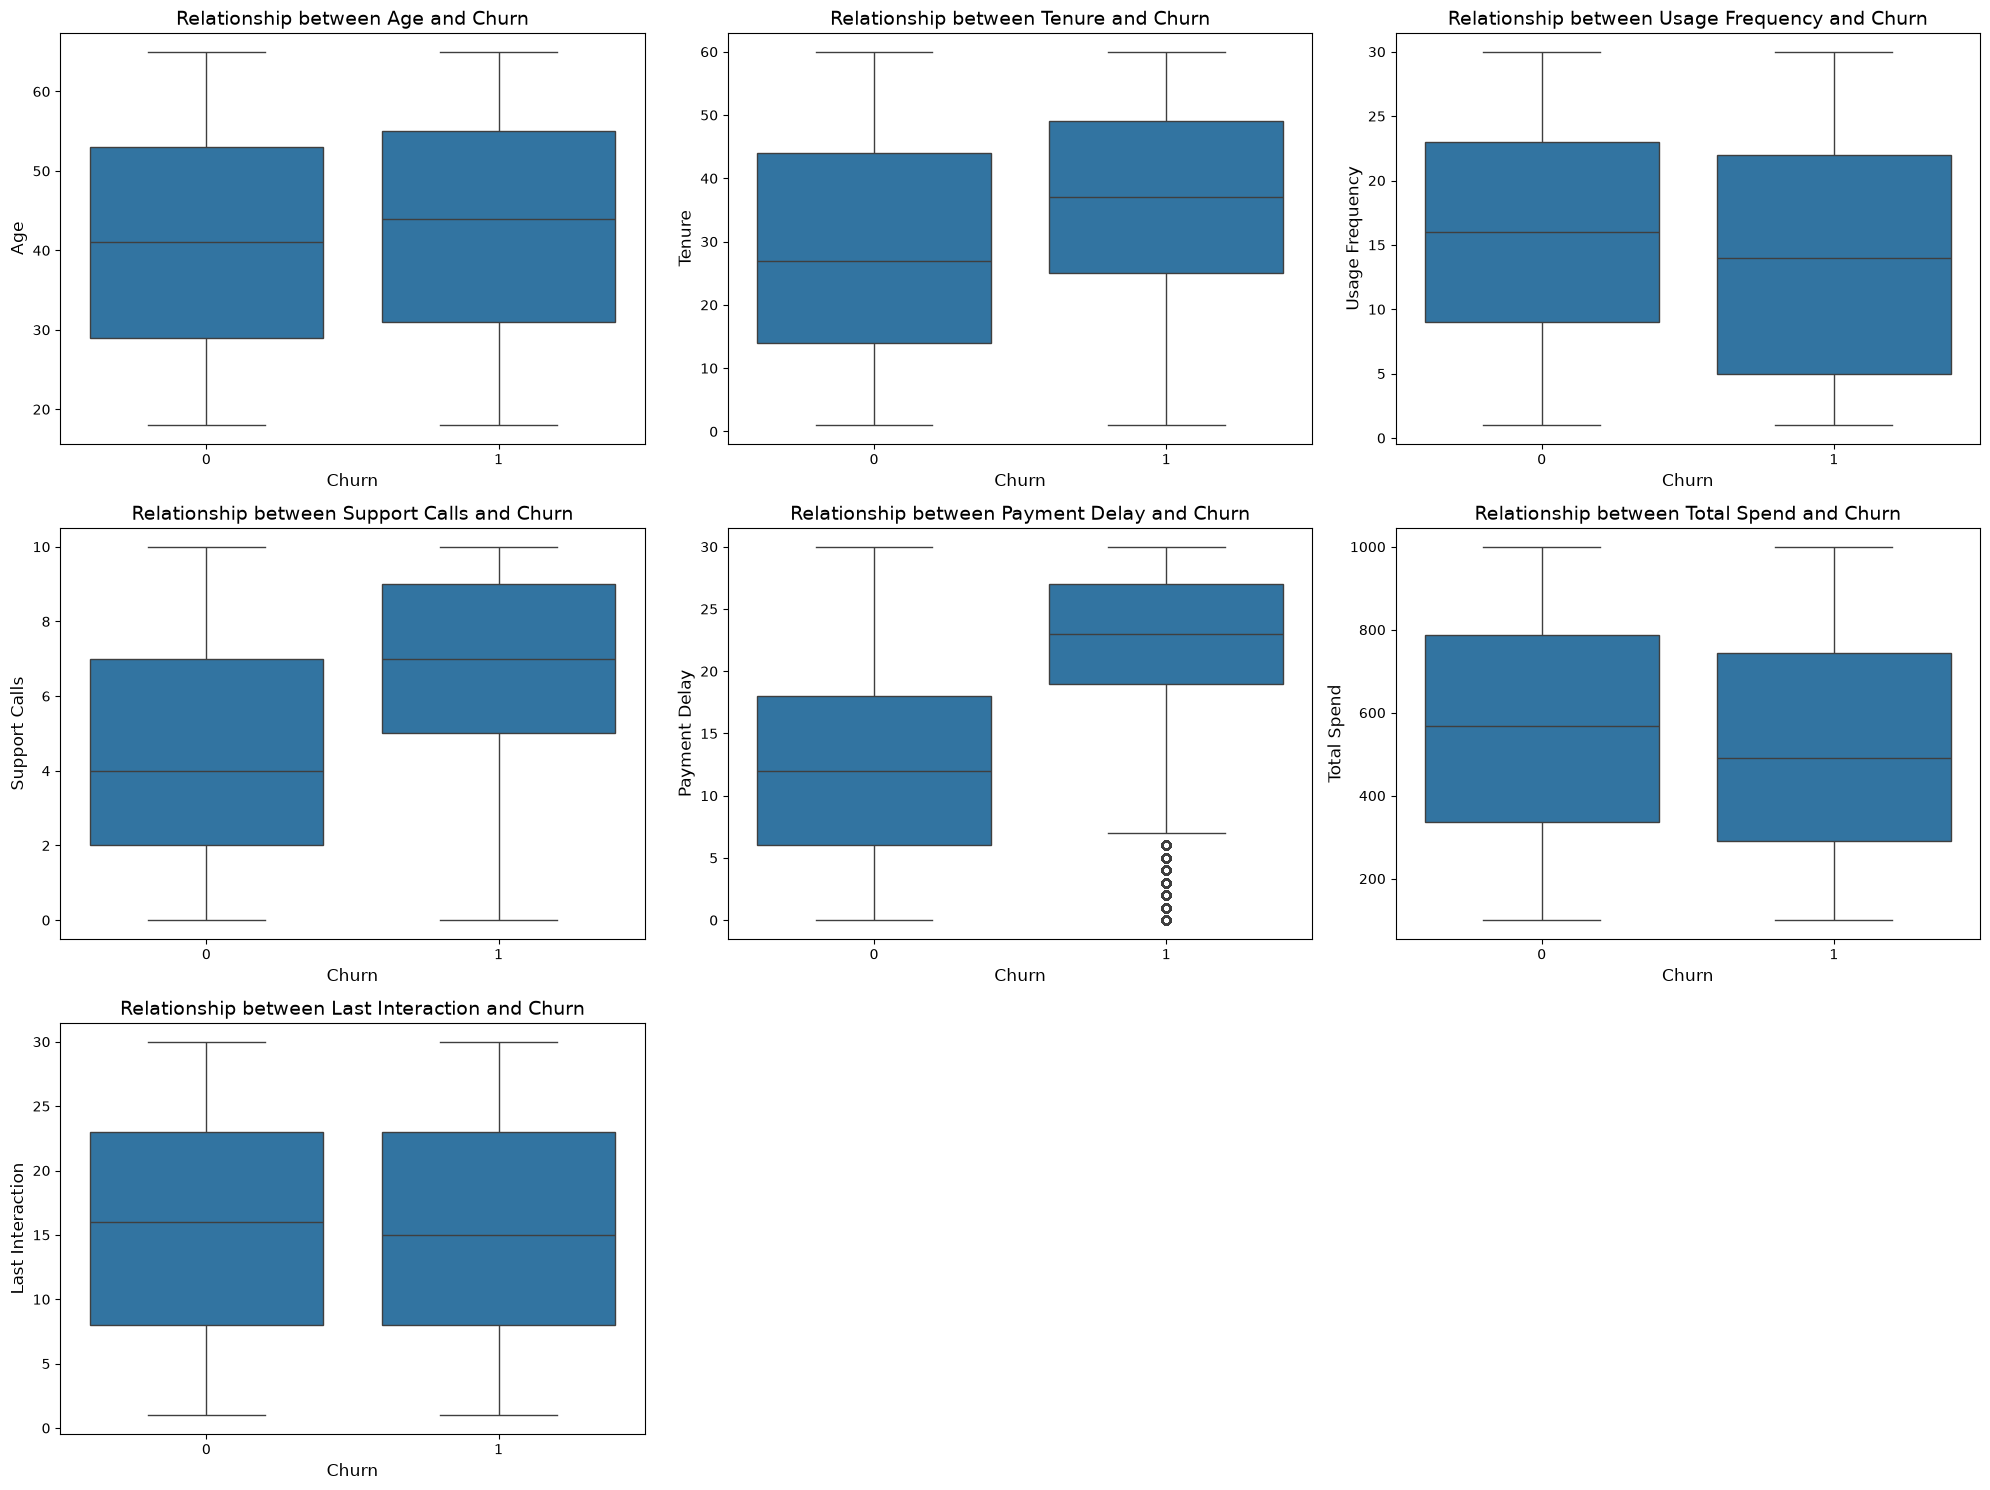

In [16]:
# Create subplots for numerical variables and their relationship with 'Churn'
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(20, 15))
axes = axes.flatten()

numerical_cols = ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 
                  'Payment Delay', 'Total Spend', 'Last Interaction']

for i, col in enumerate(numerical_cols):
    sns.boxplot(x='Churn', y=col, data=dataset, ax=axes[i])
    axes[i].set_title(f'Relationship between {col} and Churn', fontsize=14)
    axes[i].set_xlabel('Churn', fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)

# Remove empty subplots if any
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Biến số (Numerical Variables):

1. Age (Tuổi):
- Trung vị (median):
    - Nhóm Non-Churn (Churn=0): Trung vị nằm khoảng 40 tuổi.
    - Nhóm Churn (Churn=1): Trung vị cao hơn, nằm khoảng 45 tuổi.
- Phạm vi phân phối (IQR - Interquartile Range):
    - Nhóm Non-Churn: Phân phối tập trung chủ yếu từ 30 đến 50 tuổi.
    - Nhóm Churn: Phân phối rộng hơn, trải dài từ 20 đến 60 tuổi.
- Kết luận:
    - Nhóm Churn có phân phối rộng hơn về độ tuổi: Khách hàng lớn tuổi hơn (45+) và khách hàng trẻ tuổi hơn (30-) sẽ có xu hướng Churn
    - Age không phải là yếu tố quyết định duy nhất trong việc khách hàng có rời bỏ hay không, phải kết hợp với các yếu tố khác

2. Tenure (Thời gian sử dụng):
- Có sự tương đồng cao giữa 2 nhóm `churn=0` và `churn=1`
- Giá trị trung vị (median) rất gần nhau (~30 tháng),
- Phạm vi phân phối (IQR) cũng rất tương đồng nhau (~10-50 tháng)
- Kết luận: Tenure không phải là yếu tổ mạnh để phân biệt giữa 2 nhóm Churn và Non-churn

3. Usage Frequency (Tần suất sử dụng):
- Tương tự, Usage Frequency cũng không phải là yếu tố mạnh để đánh giá một khách hàng có sẽ rời đi hay tiếp tục sử dụng dịch vụ

4. Support Calls (Số lần gọi hỗ trợ):
- Nhóm Non-Churn (`churn=0`):
    - Trung vị: Số lần gọi hỗ trợ không cao, với khoảng 1-2 lần.
    - Phạm vi phân phối: Hầu hết khách hàng Non-Churn có số lần gọi hỗ trợ dưới 4 lần (IQR nằm trong khoảng 0-4).
- Nhóm Churn (`churn=1`):
    - Median (trung vị) của nhóm này cao hơn rõ rệt, nằm ở khoảng 6 lần.
    - Phạm vi phân phối rộng hơn đáng kể, với nhiều khách hàng có số lần gọi hỗ trợ lên tới 8-10 lần.
- Kết luận: Support Calls là yếu tố quan trọng ảnh hưởng đến Churn
    - Nhóm Churn có số lần gọi hỗ trợ cao hơn đáng kể so với Non-Churn.
    - Nhóm Non-Churn thường không hoặc rất ít gọi hỗ trợ, cho thấy họ hài lòng với dịch vụ và không cần yêu cầu thêm.
    - Khách hàng thường xuyên gọi hỗ trợ (trên 5 lần) có xu hướng rời bỏ dịch vụ cao hơn, có thể do không hài lòng với dịch vụ

5. Payment Delay (Trễ hạn thanh toán):
- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 10 ngày.
    - Phạm vi phân phối: Tập trung trong khoảng 5-15 ngày. Có số ít khách hàng có Payment Delay vượt 20 ngày, nhưng không đáng kể
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Cao hơn đáng kể, nằm ở khoảng 15 ngày.
    - Phạm vi phân phối: Rộng hơn, với phần lớn khách hàng có Payment Delay nằm trong khoảng 10-20 ngày và trải dài đến 30 ngày.
- Kết luận: Payment Delay là một yếu tố quan trọng ảnh hưởng đến Churn:
    - Biểu đồ cho thấy rõ ràng nhiều khách hàng trong nhóm Churn có Payment Delay cao hơn nhóm Non-Churn, tức là khách hàng có thời gian chậm thanh toán dài (Payment Delay cao) có nguy cơ Churn cao hơn.
    - Phân phối rộng hơn của nhóm Churn (với nhiều khách hàng vượt quá 20 ngày) có thể phản ánh các vấn đề tài chính hoặc sự không hài lòng với dịch vụ.
    
6. Total Spend (Tổng chi tiêu):

- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 800.
    - Phạm vi phân phối: Tập trung trong khoảng 600-900, phản ánh mức chi tiêu cao hơn so với nhóm Churn.
    - Phân phối rất hẹp, với hầu hết khách hàng có chi tiêu cao và ổn định.
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Khoảng 500
    - Phạm vi phân phối: Rộng hơn so với nhóm Non-Churn, nằm trong khoảng 300-700
- Kết luận: Total Spend cũng là một yếu tố quan trọng trong việc dự đoán Churn:
    - Nhóm Churn có xu hướng chi tiêu thấp hơn đáng kể so với nhóm Non-Churn.
    - Khách hàng chi tiêu ít (<600) thường có nguy cơ Churn cao
  
7. Last Interaction (Thời gian tương tác cuối cùng):
- Nhóm Churn = 0 (Non-Churn):
    - Median (Trung vị): Khoảng 10 ngày.
    - Phạm vi phân phối: Tập trung trong khoảng 5-15 ngày, với số ít khách hàng có thời gian tương tác cuối trên 20 ngày.
    - Phân phối hẹp, phản ánh rằng khách hàng Non-Churn thường có tương tác gần đây.
- Nhóm Churn = 1 (Churn):
    - Median (Trung vị): Cao hơn nhóm Non-Churn, nằm ở khoảng 15 ngày.
    - Phạm vi phân phối: Phân phối rộng hơn, nằm trong khoảng 10-20 ngày.
- Kết luận: Last Interaction cũng là 1 yếu tố ảnh hưởng đến việc khách hàng có rời đi hay không, nhưng không mạnh bằng các feature Support Calls, Payment Delay và Total Spend, nhưng mạnh hơn Tenure và Usage Frequency



## INSIGHTS:

1. Khách hàng gọi hỗ trợ nhiều thường có xu hướng rời đi, có thể do trải nghiệm dịch vụ mang lại không đủ tốt
2. Tài chính yếu: Khách hàng có nguy cơ Churn thường gặp vấn đề về tài chính (Payment Delay cao, Total Spend thấp, Monthly Contract).
3. Khách hàng là nữ thường có xu hướng rời đi nhiều hơn nam
4. Khách hàng cao tuổi (50+) và khách hàng thanh thiếu niên (30-) có xu hướng rời bỏ dịch vụ
5. Gắn bó thấp: Những khách hàng ít sử dụng dịch vụ, ít tương tác gần đây, thường dễ rời bỏ do có thể bất mãn với hỗ trợ khách hàng.

## 3. Phân tích mối tương quan giữa các biến số

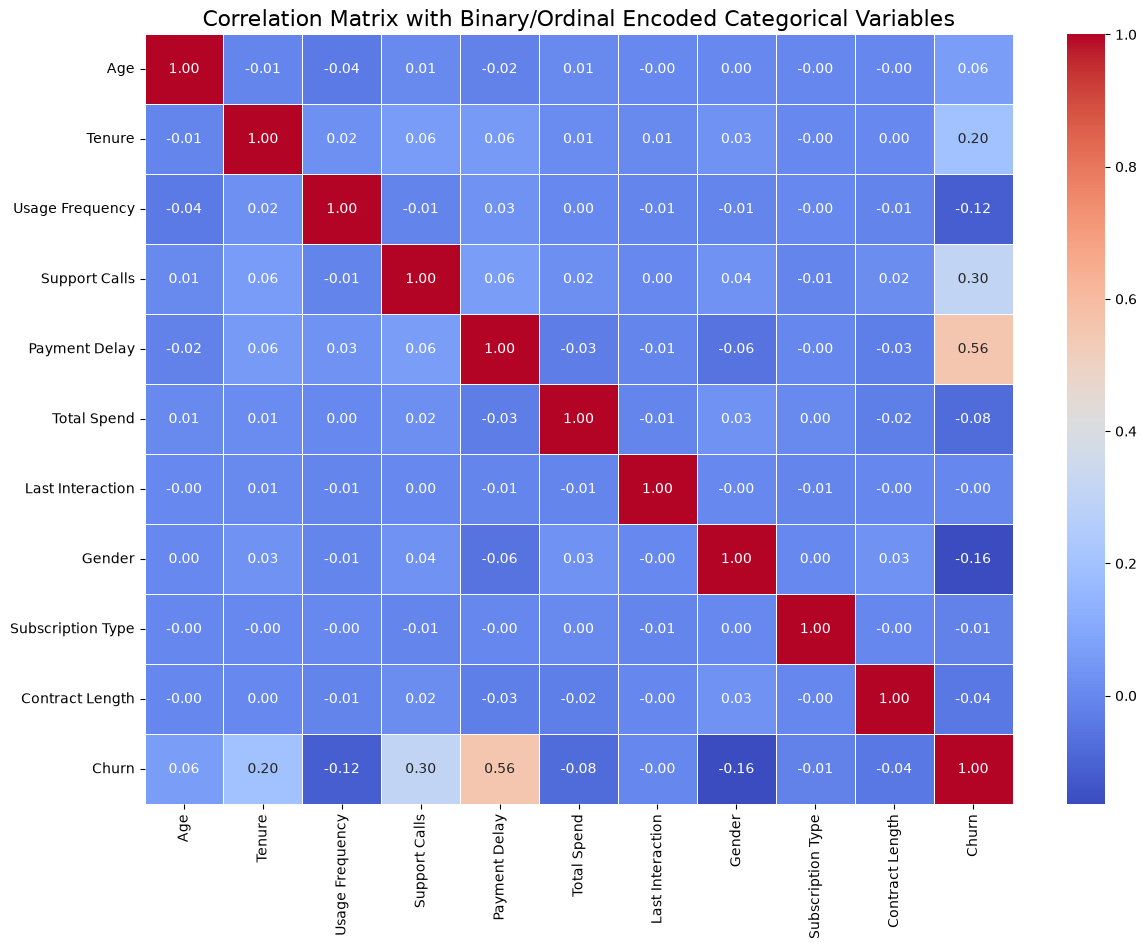

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender,Subscription Type,Contract Length,Churn
Age,1.000000,-0.007763,-0.038331,0.005014,-0.016132,0.006490,-0.000148,0.001800,-0.001730,-0.001181,0.063457
Tenure,-0.007763,1.000000,0.023485,0.060065,0.055963,0.009474,0.005770,0.029418,-0.000392,0.002505,0.195327
Usage Frequency,-0.038331,0.023485,1.000000,-0.014072,0.031132,0.001527,-0.009192,-0.006907,-0.000010,-0.012548,-0.115098
Support Calls,0.005014,0.060065,-0.014072,1.000000,0.064298,0.021750,0.001666,0.035418,-0.005929,0.015806,0.304631
Payment Delay,-0.016132,0.055963,0.031132,0.064298,1.000000,-0.031119,-0.008076,-0.058578,-0.004202,-0.025665,0.557386
Total Spend,0.006490,0.009474,0.001527,0.021750,-0.031119,1.000000,-0.007692,0.029337,0.004178,-0.024707,-0.078867
Last Interaction,-0.000148,0.005770,-0.009192,0.001666,-0.008076,-0.007692,1.000000,-0.000472,-0.005606,-0.002611,-0.002818
Gender,0.001800,0.029418,-0.006907,0.035418,-0.058578,0.029337,-0.000472,1.000000,0.003434,0.029300,-0.164549
Subscription Type,-0.001730,-0.000392,-0.000010,-0.005929,-0.004202,0.004178,-0.005606,0.003434,1.000000,-0.002531,-0.014555
Contract Length,-0.001181,0.002505,-0.012548,0.015806,-0.025665,-0.024707,-0.002611,0.029300,-0.002531,1.000000,-0.044830


In [17]:
# Encode Gender and other categorical variables with ordinal/binary encoding
# Gender: Male = 1, Female = 0
encoded_data_binary = dataset.copy()
encoded_data_binary['Gender'] = encoded_data_binary['Gender'].apply(lambda x: 1 if x == 'Male' else 0)

# Subscription Type: Basic = 0, Standard = 1, Premium = 2
subscription_map = {'Basic': 0, 'Standard': 1, 'Premium': 2}
encoded_data_binary['Subscription Type'] = encoded_data_binary['Subscription Type'].map(subscription_map)

# Contract Length: Monthly = 0, Quarterly = 1, Annual = 2
contract_map = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
encoded_data_binary['Contract Length'] = encoded_data_binary['Contract Length'].map(contract_map)

# Combine numerical and newly encoded categorical columns
all_columns_binary = numerical_cols + ['Gender', 'Subscription Type', 'Contract Length', 'Churn']

# Compute the correlation matrix
correlation_matrix_binary = encoded_data_binary[all_columns_binary].corr()

# Plot the heatmap for correlations
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix_binary, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix with Binary/Ordinal Encoded Categorical Variables", fontsize=16)
plt.show()

# Return the correlation matrix for review
correlation_matrix_binary

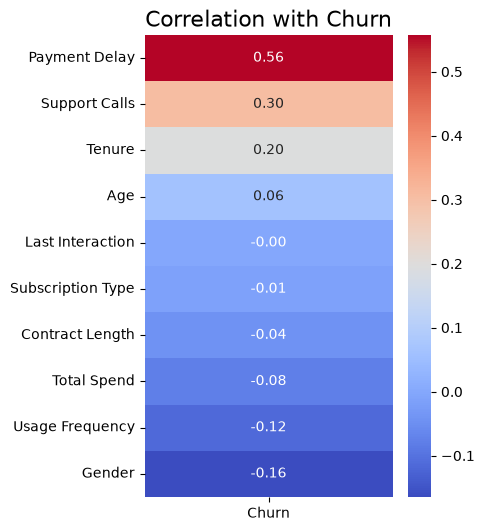

Payment Delay        0.557386
Support Calls        0.304631
Tenure               0.195327
Age                  0.063457
Last Interaction    -0.002818
Subscription Type   -0.014555
Contract Length     -0.044830
Total Spend         -0.078867
Usage Frequency     -0.115098
Gender              -0.164549
Name: Churn, dtype: float64

In [18]:
# Calculate correlation of all variables with the target (Churn)
target_corr = correlation_matrix_binary['Churn'].drop('Churn').sort_values(ascending=False)

# Plot the correlation of each variable with Churn
plt.figure(figsize=(4, 6))
sns.heatmap(target_corr.to_frame(), annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Correlation with Churn", fontsize=16)
plt.show()

# Display the correlations for reference
target_corr

# Model

1. Mục tiêu: Xây dựng 1 mô hình học máy để dự đoán khách hàng sẽ rời đi hay tiếp tục ở lại sử dụng dịch vụ từ các thông tin đã cho
- Input: Giá trị của tất cả các field trong dataset, trừ cột `churn` là target dự đoán.
- Output: Giá trị `churn`:
    - `churn=0`: Khách hàng tiếp tục ở lại
    - `churn=1`: Khách hàng rời đi, không sử dụng dịch vụ nữa

2. Model: Một số mô hình học máy phù hợp với bài toán Classification
- Logistic Regression:
- SVM:
- kNN:
- Decision Tree:
- Random Forest:

3. Lưu ý: 
- Đối với các cột có kiểu dữ liệu thuộc loại Categorical như `Gender`, `Subscription Type`, `Contract Length`: Phải tiền xử lý chúng thành các giá trị Numerical để có thể đưa vào được model
- Dữ liệu không bị mất cân bằng (~ 45% `churn=0` và ~ 55% `churn=1`) -> Không cần thiết phải cân bằng dữ liệu bằng các kỹ thuật như SMOTE, Undersampling.

## 1. Chuẩn hoá dữ liệu dạng Categorical thành dạng Numerical

In [19]:
# Encode categorical variables to numeric values
encoded_dataset = dataset.copy()
encoded_dataset['Gender'] = encoded_dataset['Gender'].apply(lambda x: 1 if x == 'Male' else 0)

subscription_map = {'Basic': 0, 'Standard': 1, 'Premium': 2}
encoded_dataset['Subscription Type'] = encoded_dataset['Subscription Type'].map(subscription_map)

contract_map = {'Monthly': 0, 'Quarterly': 1, 'Annual': 2}
encoded_dataset['Contract Length'] = encoded_dataset['Contract Length'].map(contract_map)

In [20]:
encoded_dataset

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,0,25,14,4,27,0,0,598,9,1
1,2,41,0,28,28,7,13,1,0,584,20,0
2,3,47,1,27,10,2,29,2,2,757,21,0
3,4,35,1,9,12,5,17,2,1,232,18,0
4,5,53,0,58,24,9,2,1,2,533,18,0
...,...,...,...,...,...,...,...,...,...,...,...,...
64369,64370,45,0,33,12,6,21,0,1,947,14,1
64370,64371,37,1,6,1,5,22,1,2,923,9,1
64371,64372,25,1,39,14,8,30,2,0,327,20,1
64372,64373,50,0,18,19,7,22,1,0,540,13,1


## 2. Chuẩn bị dữ liệu

In [21]:
from sklearn.linear_model import LogisticRegression 
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

### Chuẩn bị features (X) - labels (y)

In [22]:
X = encoded_dataset.drop('Churn', axis=1)
y = encoded_dataset['Churn']

### Chia dữ liệu thành 2 phần: training set (90%) và test set (10%)

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify=y)

In [24]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((57936, 11), (6438, 11), (57936,), (6438,))

In [25]:
# Standardize numerical features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Các mô hình học máy

In [26]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC()
}

Processing: Logistic Regression...
	Model: Logistic Regression
	Accuracy: 0.8612923268095682
	Precision: 0.8601001669449082
	Recall: 0.8445901639344262
	F1 Score: 0.8522746071133168
	Training Time (s): 0.04014158248901367
	Prediction Time (s): 0.0009996891021728516


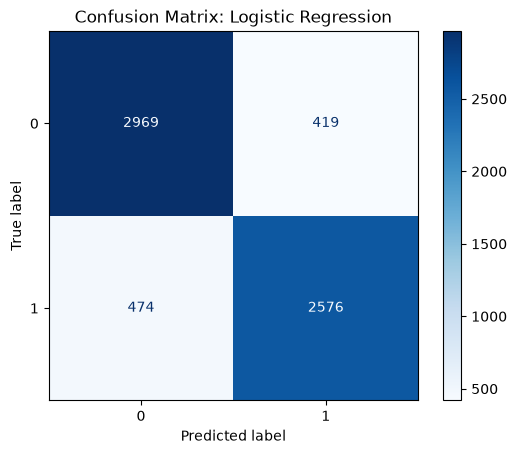

Processing: Decision Tree...
	Model: Decision Tree
	Accuracy: 0.9981360671015843
	Precision: 0.9977064220183486
	Recall: 0.9983606557377049
	F1 Score: 0.9980334316617503
	Training Time (s): 0.06999850273132324
	Prediction Time (s): 0.0010006427764892578


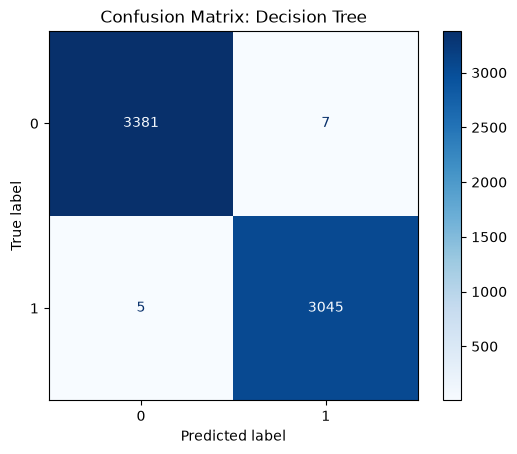

Processing: kNN...
	Model: kNN
	Accuracy: 0.9328984156570364
	Precision: 0.9300262812089356
	Recall: 0.9281967213114755
	F1 Score: 0.929110600590745
	Training Time (s): 0.10217738151550293
	Prediction Time (s): 0.8528633117675781


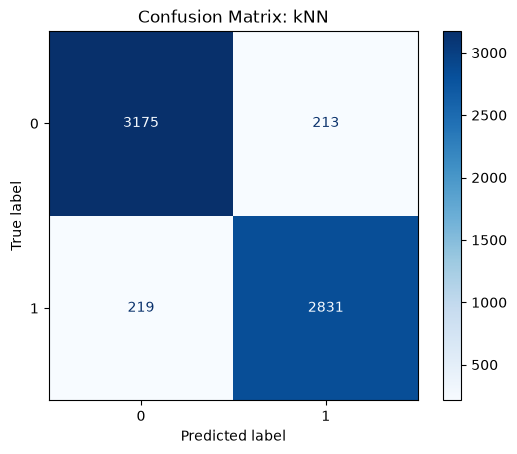

Processing: Random Forest...
	Model: Random Forest
	Accuracy: 0.9972041006523765
	Precision: 0.9996704021094265
	Recall: 0.9944262295081967
	F1 Score: 0.9970414201183432
	Training Time (s): 2.6908862590789795
	Prediction Time (s): 0.03935647010803223


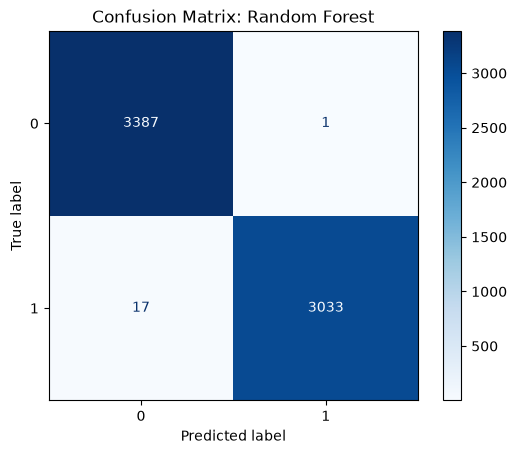

Processing: SVM...
	Model: SVM
	Accuracy: 0.9547996272134203
	Precision: 0.9566368752068851
	Recall: 0.9475409836065574
	F1 Score: 0.9520672047438643
	Training Time (s): 23.871695280075073
	Prediction Time (s): 5.937354803085327


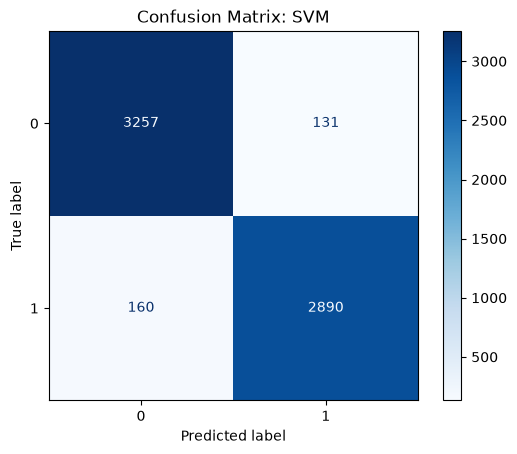

In [27]:
import time
# Initialize lists to store ROC data
roc_data = {}

# Train, evaluate, and collect ROC curve data
timed_results = []

for model_name, model in models.items():
    print(f'Processing: {model_name}...')
    
    # Measure training time
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time

    # Measure prediction time
    start_time = time.time()
    y_pred = model.predict(X_test_scaled)
    predict_time = time.time() - start_time
    
    # Get probabilities for ROC curve if available
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        y_prob = model.decision_function(X_test_scaled)
    else:
        y_prob = None
    
    # Evaluate metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "Training Time (s)": train_time,
        "Prediction Time (s)": predict_time
    }
    for key, value in metrics.items():
        print(f'\t{key}: {value}')
    timed_results.append(metrics)
    print('==============================')
    
    # Collect ROC curve data
    if y_prob is not None:
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_data[model_name] = (fpr, tpr, roc_auc)
    
    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_ if hasattr(model, "classes_") else [0, 1])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.show()

# Convert results to DataFrame
timed_results_df = pd.DataFrame(timed_results)

In [28]:
timed_results_df

,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.861292,0.860100,0.844590,0.852275,0.040142,0.001000
1,Decision Tree,0.998136,0.997706,0.998361,0.998033,0.069999,0.001001
2,kNN,0.932898,0.930026,0.928197,0.929111,0.102177,0.852863
3,Random Forest,0.997204,0.999670,0.994426,0.997041,2.690886,0.039356
4,SVM,0.954800,0.956637,0.947541,0.952067,23.871695,5.937355


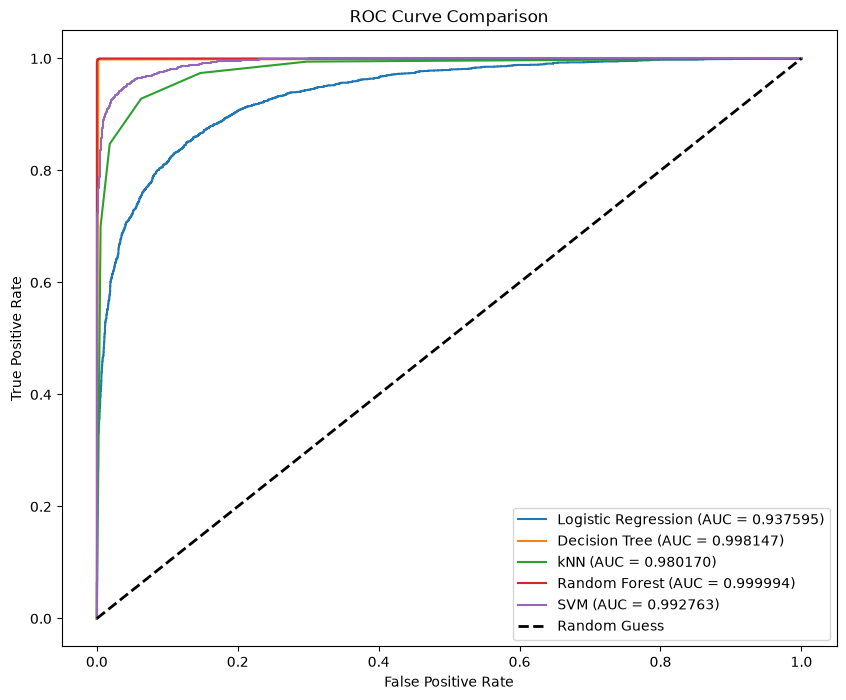

In [29]:
# Plot ROC curves for all models
plt.figure(figsize=(10, 8))
for model_name, roc_values in roc_data.items():
    fpr, tpr, roc_auc = roc_values
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {roc_auc:.6f})")
plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess')
plt.title("ROC Curve Comparison")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.show()

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import statsmodels.api as sm

# 1. Đọc dữ liệu
dataset = pd.read_csv('dataset.csv')

# 2. Làm sạch dữ liệu khuyết thiếu
dataset = dataset.dropna()

# 3. Phân loại biến
target_col = 'Churn'
drop_cols = ['CustomerID', target_col]

X = dataset.drop(columns=drop_cols)
y = dataset[target_col]

# Xác định danh sách cột định số và cột định tính
num_cols = X.select_dtypes(include=['float64', 'int64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print(f"Cột định lượng (Numerical): {num_cols}")
print(f"Cột định tính (Categorical): {cat_cols}")

# 4. Chia tập Train/Test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Cột định lượng (Numerical): ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction']
Cột định tính (Categorical): ['Gender', 'Subscription Type', 'Contract Length']


In [31]:
# --- 1. Tạo Tiền xử lý cho Logistic Regression (OneHotEncoding + Chuẩn hóa StandardScaler) ---
preprocessor_logreg = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

# Biến đổi dữ liệu
X_train_logreg = preprocessor_logreg.fit_transform(X_train)
X_test_logreg = preprocessor_logreg.transform(X_test)

# Lấy tên cột sau khi One-Hot Encoding
encoded_cat_names = preprocessor_logreg.named_transformers_['cat'].get_feature_names_out(cat_cols)
feature_names = num_cols + list(encoded_cat_names)

# --- 2. Huấn luyện Logistic Regression ---
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_logreg, y_train)

# --- 3. Trích xuất Hệ số Beta và Odds Ratio (Dùng giải thích trong nghiên cứu) ---
coefficients = log_reg.coef_[0]
odds_ratios = np.exp(coefficients)

df_interpret = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient (Beta)': coefficients,
    'Odds Ratio (e^Beta)': odds_ratios
}).sort_values(by='Odds Ratio (e^Beta)', ascending=False)

print("="*60)
print("BẢNG GIẢI THÍCH TÁC ĐỘNG CỦA CÁC YẾU TỐ (LOGISTIC REGRESSION)")
print("="*60)
print(df_interpret.to_string(index=False))

# --- 4. Đánh giá mô hình Logistic Regression ---
y_pred_logreg = log_reg.predict(X_test_logreg)
y_proba_logreg = log_reg.predict_proba(X_test_logreg)[:, 1]

print("\n--- BÁO CÁO HIỆU NĂNG LOGISTIC REGRESSION ---")
print(classification_report(y_test, y_pred_logreg))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_logreg):.4f}")

BẢNG GIẢI THÍCH TÁC ĐỘNG CỦA CÁC YẾU TỐ (LOGISTIC REGRESSION)
                   Feature  Coefficient (Beta)  Odds Ratio (e^Beta)
             Payment Delay            1.893090             6.639854
             Support Calls            1.035302             2.815957
                    Tenure            0.597890             1.818278
   Contract Length_Monthly            0.340318             1.405395
                       Age            0.271556             1.312004
          Last Interaction           -0.005333             0.994681
Subscription Type_Standard           -0.065367             0.936724
 Subscription Type_Premium           -0.103829             0.901379
 Contract Length_Quarterly           -0.166463             0.846654
               Total Spend           -0.258750             0.772016
           Usage Frequency           -0.523457             0.592469
               Gender_Male           -1.140257             0.319737

--- BÁO CÁO HIỆU NĂNG LOGISTIC REGRESSION ---
       

In [32]:
# Thêm cột Intercept cho statsmodels
X_train_sm = sm.add_constant(X_train_logreg)

# Chạy mô hình Logit của statsmodels
logit_model = sm.Logit(y_train.values, X_train_sm)
result = logit_model.fit(disp=False)

# In tóm tắt thống kê (Bao gồm p-value & Khoảng tin cậy 95%)
summary_df = pd.DataFrame({
    'Feature': ['Intercept'] + feature_names,
    'Coef': result.params,
    'Std Err': result.bse,
    'z-score': result.tvalues,
    'P-value (P>|z|)': result.pvalues,
    'Odds Ratio': np.exp(result.params)
})

print("="*60)
print("BẢNG KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (STATSMODELS LOGIT)")
print("="*60)
print(summary_df.to_string(index=False))

BẢNG KIỂM ĐỊNH Ý NGHĨA THỐNG KÊ (STATSMODELS LOGIT)
                   Feature      Coef  Std Err    z-score  P-value (P>|z|)  Odds Ratio
                 Intercept  0.190908 0.030215   6.318328     2.644081e-10    1.210349
                       Age  0.271719 0.012578  21.603221    1.675189e-103    1.312218
                    Tenure  0.598189 0.013091  45.693923     0.000000e+00    1.818822
           Usage Frequency -0.523790 0.012971 -40.380386     0.000000e+00    0.592272
             Support Calls  1.035882 0.014277  72.557770     0.000000e+00    2.817589
             Payment Delay  1.893902 0.017661 107.235547     0.000000e+00    6.645251
               Total Spend -0.258767 0.012598 -20.540840     9.294204e-94    0.772003
          Last Interaction -0.005313 0.012463  -0.426305     6.698859e-01    0.994701
               Gender_Male -1.142089 0.025992 -43.940551     0.000000e+00    0.319152
 Subscription Type_Premium -0.102382 0.030507  -3.355980     7.908438e-04    0.902685
Su


--- BÁO CÁO HIỆU NĂNG DECISION TREE ---
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      6776
           1       0.89      0.87      0.88      6099

    accuracy                           0.89     12875
   macro avg       0.89      0.89      0.89     12875
weighted avg       0.89      0.89      0.89     12875

ROC-AUC Score: 0.9688


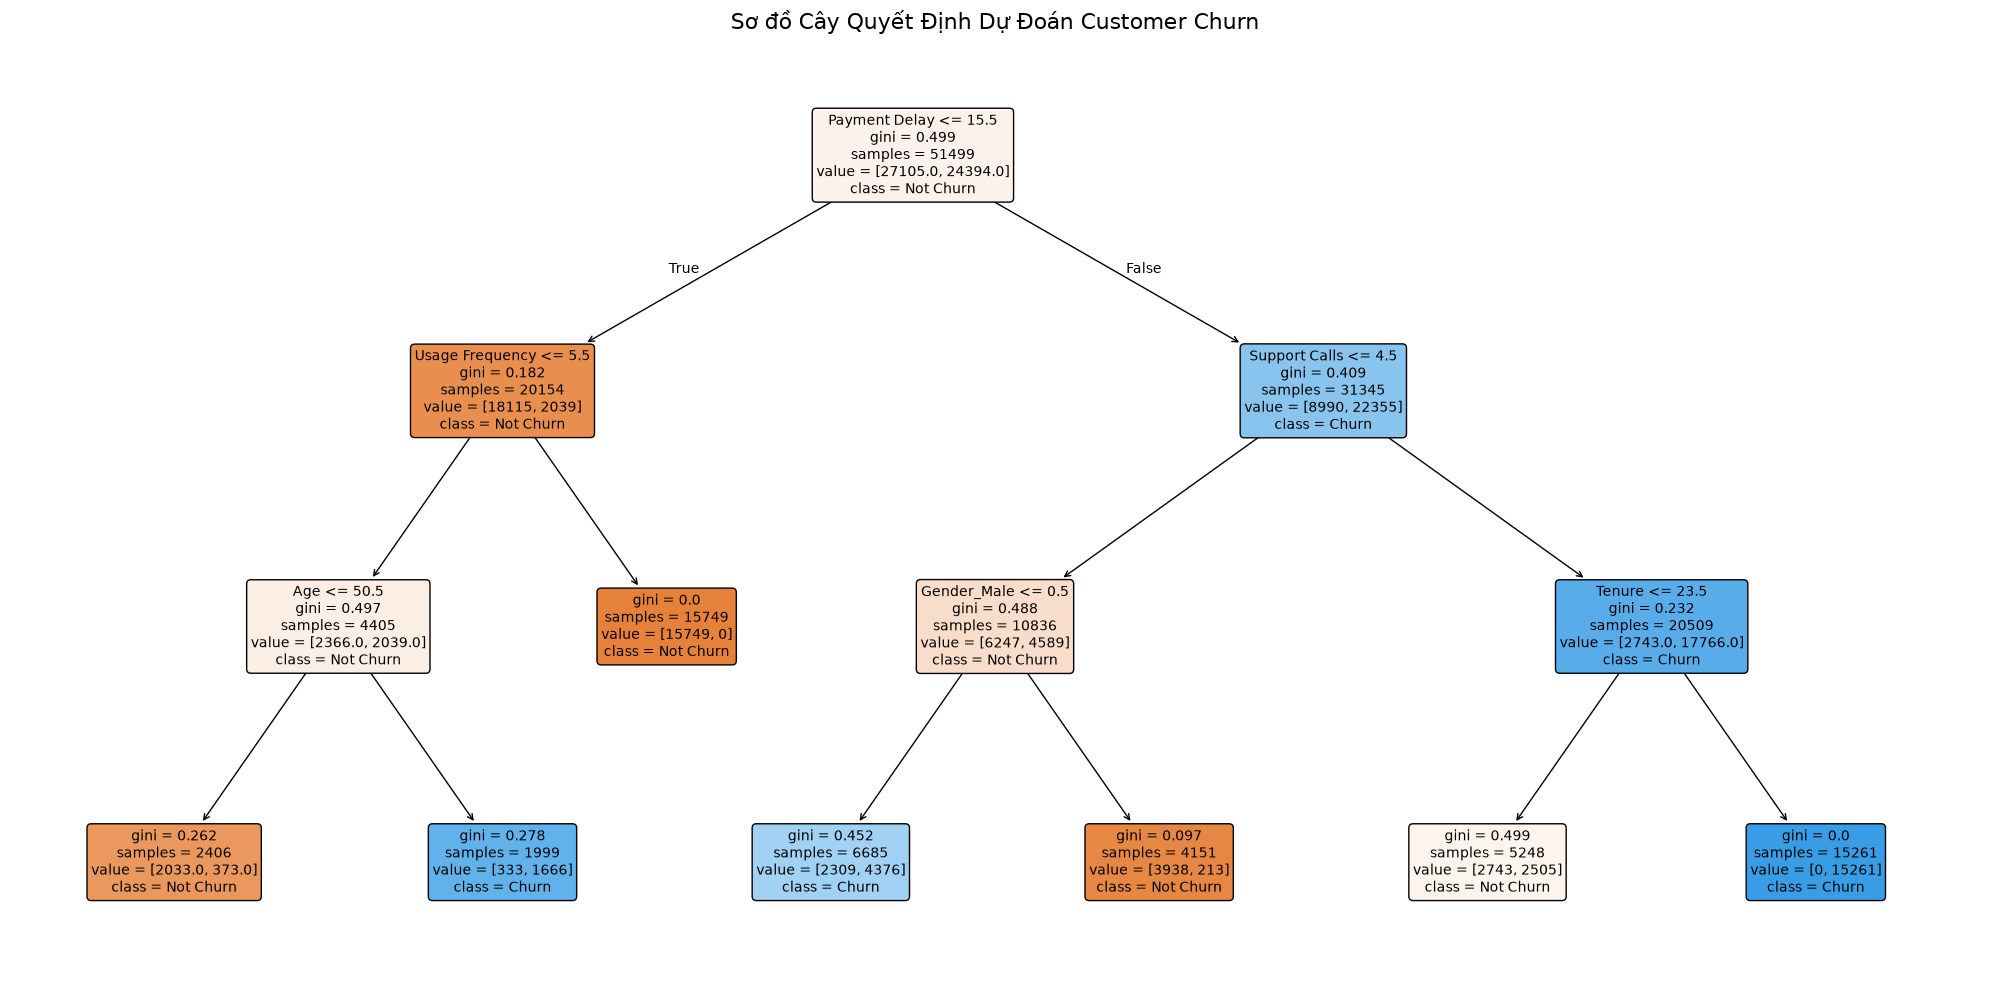


--- BỘ QUY TẮC QUYẾT ĐỊNH (IF-THEN RULES) ---
|--- Payment Delay <= 15.50
|   |--- Usage Frequency <= 5.50
|   |   |--- Age <= 50.50
|   |   |   |--- class: 0
|   |   |--- Age >  50.50
|   |   |   |--- class: 1
|   |--- Usage Frequency >  5.50
|   |   |--- class: 0
|--- Payment Delay >  15.50
|   |--- Support Calls <= 4.50
|   |   |--- Gender_Male <= 0.50
|   |   |   |--- class: 1
|   |   |--- Gender_Male >  0.50
|   |   |   |--- class: 0
|   |--- Support Calls >  4.50
|   |   |--- Tenure <= 23.50
|   |   |   |--- class: 0
|   |   |--- Tenure >  23.50
|   |   |   |--- class: 1



In [33]:
# --- 1. Tiền xử lý riêng cho Cây quyết định (Giữ nguyên tỉ lệ biến số) ---
preprocessor_dt = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_cols)
    ]
)

X_train_dt = preprocessor_dt.fit_transform(X_train)
X_test_dt = preprocessor_dt.transform(X_test)

# --- 2. Huấn luyện Decision Tree (Giới hạn max_depth=3 hoặc 4 để dễ đọc cây) ---
tree_model = DecisionTreeClassifier(
    max_depth=3,            # Giới hạn độ sâu để mô hình không bị phức tạp
    criterion='gini',
    min_samples_leaf=100,  # Tránh phân nhánh rác
    random_state=42
)
tree_model.fit(X_train_dt, y_train)

# --- 3. Đánh giá Decision Tree ---
y_pred_tree = tree_model.predict(X_test_dt)
y_proba_tree = tree_model.predict_proba(X_test_dt)[:, 1]

print("\n--- BÁO CÁO HIỆU NĂNG DECISION TREE ---")
print(classification_report(y_test, y_pred_tree))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_tree):.4f}")

# --- 4. Trực quan hóa Cây quyết định ---
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=['Not Churn', 'Churn'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Sơ đồ Cây Quyết Định Dự Đoán Customer Churn", fontsize=16)
plt.tight_layout()
plt.show()

# --- 5. In luật quyết định (If-Then Rules) dạng Text ---
print("\n--- BỘ QUY TẮC QUYẾT ĐỊNH (IF-THEN RULES) ---")
tree_rules = export_text(tree_model, feature_names=feature_names)
print(tree_rules)

## 4. Mạng neural network học sâu

In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Precision, Recall

ModuleNotFoundError: No module named 'tensorflow'

In [ ]:
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Output layer with sigmoid for binary classification
])

/opt/conda/lib/python3.10/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='binary_crossentropy',
              metrics=[
                    'accuracy', 
                    Precision(), 
                    Recall()
                    ]
             )

In [ ]:
# Train
start_time = time.time()
history = model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=5, batch_size=32, verbose=1)
train_time = time.time() - start_time

Epoch 1/5
9919/9919 ━━━━━━━━━━━━━━━━━━━━ 19s 2ms/step - accuracy: 0.9641 - loss: 0.0960 - precision: 0.9625 - recall: 0.9770 - val_accuracy: 0.9919 - val_loss: 0.0217 - val_precision: 0.9899 - val_recall: 0.9959
Epoch 2/5
9919/9919 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - accuracy: 0.9905 - loss: 0.0255 - precision: 0.9893 - recall: 0.9940 - val_accuracy: 0.9942 - val_loss: 0.0155 - val_precision: 0.9928 - val_recall: 0.9970
Epoch 3/5
9919/9919 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - accuracy: 0.9923 - loss: 0.0203 - precision: 0.9921 - recall: 0.9944 - val_accuracy: 0.9942 - val_loss: 0.0145 - val_precision: 0.9941 - val_recall: 0.9957
Epoch 4/5
9919/9919 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - accuracy: 0.9934 - loss: 0.0170 - precision: 0.9938 - recall: 0.9945 - val_accuracy: 0.9947 - val_loss: 0.0130 - val_precision: 0.9938 - val_recall: 0.9968
Epoch 5/5
9919/9919 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step - accuracy: 0.9937 - loss: 0.0158 - precision: 0.9943 - recall: 0.9947 - val_accuracy: 0.9954 - va

In [ ]:
# Test
start_time = time.time()
y_pred_prob_nn = model.predict(X_test_scaled)
predict_time = time.time() - start_time

# Process predictions for evaluation
y_pred_nn = (y_pred_prob_nn > 0.5).astype(int)

1378/1378 ━━━━━━━━━━━━━━━━━━━━ 1s 957us/step


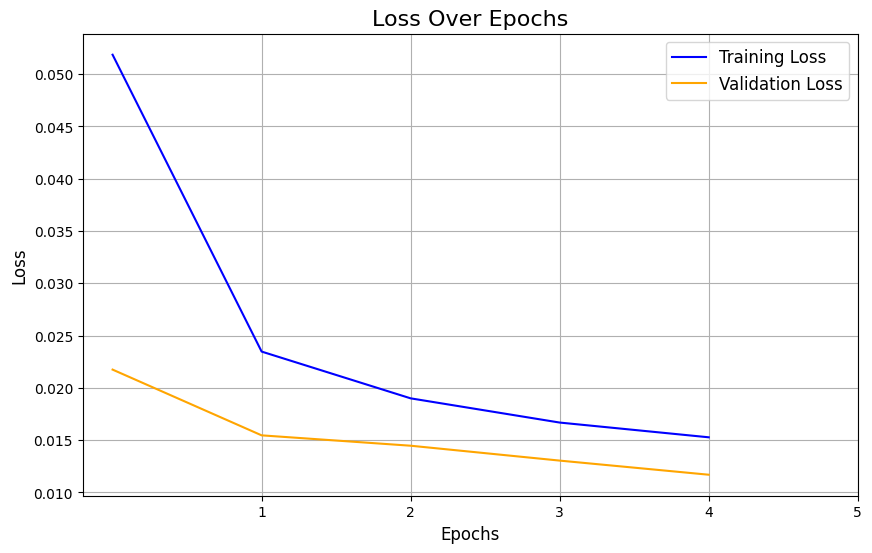

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title("Loss Over Epochs", fontsize=16)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.xticks([1,2,3,4,5])
plt.legend(fontsize=12)
plt.grid(True)
plt.show()

In [ ]:
# Evaluate metrics for Neural Network
metrics_nn = {
    "Model": "Neural Network",
    "Accuracy": accuracy_score(y_test, y_pred_nn),
    "Precision": precision_score(y_test, y_pred_nn),
    "Recall": recall_score(y_test, y_pred_nn),
    "F1 Score": f1_score(y_test, y_pred_nn),
    "Training Time (s)": train_time,
    "Prediction Time (s)": predict_time
}
print(metrics_nn)
timed_results.append(metrics_nn)

# Convert updated results to DataFrame
updated_timed_results_df = pd.DataFrame(timed_results)

updated_timed_results_df

{'Model': 'Neural Network', 'Accuracy': 0.9946692677615462, 'Precision': 0.9928750547307248, 'Recall': 0.99776, 'F1 Score': 0.9953115336272769, 'Training Time (s)': 85.5774257183075, 'Prediction Time (s)': 1.9501912593841553}


,Model,Accuracy,Precision,Recall,F1 Score,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.978586,0.981197,0.98104,0.981118,0.810583,0.001365
1,Decision Tree,0.999819,0.999720,0.99996,0.999840,0.874901,0.003193
2,kNN,0.987955,0.993705,0.98500,0.989333,1.227853,36.450838
3,Random Forest,0.999796,0.999720,0.99992,0.999820,29.831827,0.289822
4,SVM,0.993127,0.992109,0.99580,0.993951,329.318872,24.801024
5,Neural Network,0.994669,0.992875,0.99776,0.995312,85.577426,1.950191


1. Đánh giá từng chỉ số

- Độ chính xác (Accuracy):
    - Decision Tree (99.9864%) và Random Forest (99.9819%) đạt độ chính xác rất cao, gần như hoàn hảo.
    - Neural Network cũng đạt độ chính xác tốt (99.7187%).
    - Các mô hình còn lại có độ chính xác thấp hơn, nhưng Logistic Regression (97.8586%) và SVM (99.3127%) vẫn rất tốt.

- Độ chính xác dự đoán đúng lớp (Precision):
    - Decision Tree và Random Forest đạt precision rất cao, gần như hoàn hảo.
    - Neural Network (99.6805%) và kNN (99.3705%) cũng có precision tốt.
    - Logistic Regression (98.1197%) là thấp nhất trong số các mô hình.

- Tỷ lệ phát hiện đúng lớp (Recall):
    - Decision Tree (99.996%) và Random Forest (99.996%) gần như hoàn hảo.
    - Neural Network đạt recall cao (99.824%), vượt qua hầu hết các mô hình còn lại.
    - Logistic Regression (98.104%) và kNN (98.500%) thấp hơn một chút.

- F1 Score:
    - Decision Tree (99.988%) và Random Forest (99.984%) vẫn dẫn đầu.
    - Neural Network có F1 Score gần kề với (99.7522%).
    - SVM cũng đạt F1 tốt (99.3951%), vượt qua Logistic Regression và kNN.

- Thời gian huấn luyện (Training Time):
    - Decision Tree nhanh nhất (0.726s).
    - Logistic Regression và kNN cũng nhanh (1.1s).
    - SVM (243.6s) và Neural Network (98.6s) tốn thời gian đáng kể.
    - Random Forest mất 22.4s, hợp lý với độ chính xác cao.

- Thời gian dự đoán (Prediction Time):
    - Logistic Regression và Decision Tree nhanh nhất (0.001-0.003s).
    - kNN (31.68s) tốn thời gian lớn nhất do phải tính toán khoảng cách.
    - SVM (19.02s) và Neural Network (2.46s) cũng cần cải thiện.

2. Tổng kết: Lựa chọn mô hình
- Dựa vào độ chính xác và hiệu suất (Best Overall): Decision Tree và Random Forest là lựa chọn hàng đầu với hiệu suất gần như hoàn hảo, thời gian huấn luyện và dự đoán hợp lý (Accuracy, Precision, Recall, F1-score)
- Với thời gian hạn chế (Low Latency): Logistic Regression phù hợp với các bài toán yêu cầu tốc độ cao và tài nguyên hạn chế (Tổng Training time + Prediction time nhanh nhất)
- Đối với dữ liệu phức tạp và lớn: Neural Network có thể xử lý tốt hơn trong các bài toán phức tạp hơn.